# 04 · Batch export and safe feature reuse

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute. Download: 0 bytes. Uses the same real AEF 2021
Bay Area 5933-cell data and WorldCover labels (CC-BY-4.0) as notebook 03.
AEF overview vectors and GLE geographic priors have different spatial support
and input semantics. This notebook teaches
portable exports and ID alignment instead of claiming a fair model comparison.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")
from earth_embedding.demo import align_samples, classify_demo, DemoData

CPU demo; outputs are saved in ./outputs


In [2]:
bayarea = load_demo("bayarea")
parts = []
for start in range(0, len(bayarea.samples), 128):
    ids = bayarea.samples.tile_id.iloc[start:start+128].to_numpy(dtype="U")
    x = bayarea.features[start:start+128]
    path = out / f"batch-{start:04d}.npz"
    np.savez_compressed(path, tile_id=ids, features=x)
    parts.append(path)
print(f"Exported {len(parts)} ID-bearing batches; no model inference needed.")

Exported 47 ID-bearing batches; no model inference needed.


In [3]:
ids, arrays = [], []
for path in reversed(parts):  # Deliberately read in a different order.
    with np.load(path, allow_pickle=False) as z:
        ids.extend(z["tile_id"].tolist())
        arrays.append(z["features"])
aligned = align_samples(bayarea.samples, np.array(ids), np.vstack(arrays))
np.testing.assert_array_equal(aligned, bayarea.features)
reused = classify_demo(DemoData(bayarea.samples, aligned, bayarea.metadata))
print("Shuffled-batch round trip: exact feature equality.")
print({key: reused["metrics"][key] for key in ["oa", "macro_f1", "balanced_accuracy"]})

Shuffled-batch round trip: exact feature equality.
{'oa': 0.9139438564196962, 'macro_f1': 0.8748814661172164, 'balanced_accuracy': 0.8564632366572049}


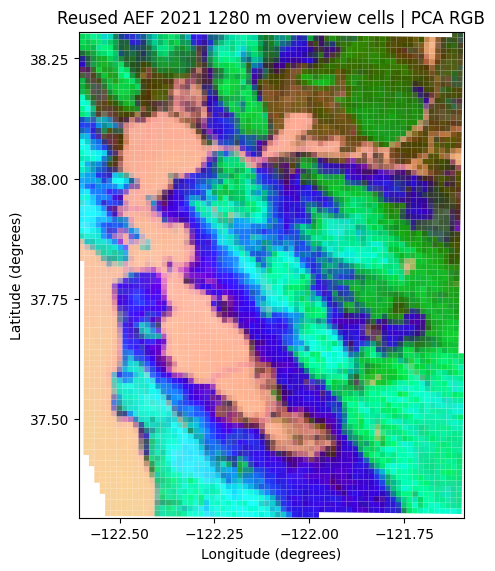

In [4]:
fig = plot_map(bayarea.samples, pca_colors(aligned), title="Reused AEF 2021 1280 m overview cells | PCA RGB")
fig.savefig(out / "reused-pca.png", dpi=160)
plt.show()

Every export includes stable IDs. `align_samples` rejects duplicate IDs,
unequal ID sets and nonfinite features. It never joins by an implicit row order.
When bringing your own data, preserve source/year/license and spatial support,
document exclusions, and design a geographic holdout before looking at scores.